# From realized to implied volatility

**One underlying, two observations.** With realized volatility you observe a price path and measure how much it moved. With implied volatility (IV) you observe what an option costs today and ask what volatility makes a pricing model reproduce that cost. Both can describe the same stock, index or other underlying.

Follow a single call quote into a volatility number, look across strikes, then compare an actual index of option prices with the S&P 500 path that followed.

## 1 · Read an option price backwards

A European call pays the amount by which the underlying finishes above the strike, or zero otherwise. With other inputs fixed, more uncertainty raises the call’s model value: the holder participates in the upside and can let the option expire worthless. The blue curve prices the call at different volatilities. Read **across from the quote and down to the volatility axis**.

Use a hypothetical 30-day call with spot and strike both 100, zero interest and dividends. Change `quote` and rerun this cell to see how the inferred annualized IV changes.

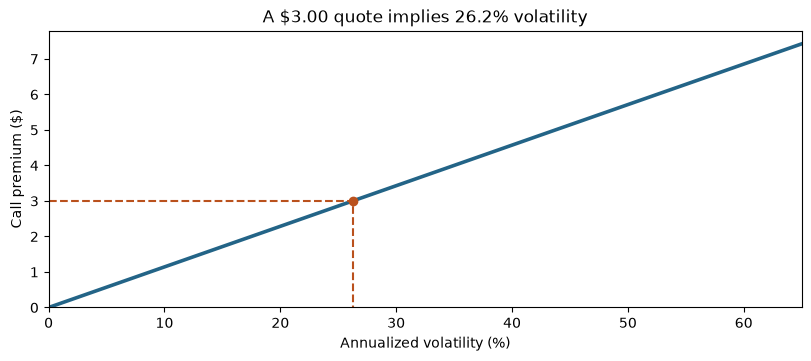

Repriced at the inferred IV: $3.0000


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src.options import call_price, implied_volatility

spot = strike = 100
years = 30 / 365
quote = 3.00  # Illustrative premium per share in dollars
iv = implied_volatility(quote, spot, strike, years)
vol_grid = np.linspace(0, max(0.65, 1.4 * iv), 180)
premiums = [call_price(spot, strike, years, 0, 0, vol) for vol in vol_grid]

fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.plot(vol_grid * 100, premiums, color="#236487", linewidth=2.6)
ax.plot([0, iv * 100, iv * 100], [quote, quote, 0], "--", color="#ba511d")
ax.scatter(iv * 100, quote, color="#ba511d", zorder=3)
ax.set(xlim=(0, vol_grid[-1] * 100), ylim=(0, None), xlabel="Annualized volatility (%)",
       ylabel="Call premium ($)", title=f"A ${quote:.2f} quote implies {iv:.1%} volatility")
plt.show()
print(f"Repriced at the inferred IV: ${call_price(spot, strike, years, 0, 0, iv):.4f}")

## 2 · One expiry can have several implied volatilities

Real option chains contain a quote for each strike. Even with the same underlying and expiry, their prices can imply different volatilities. This **skew** tells you that a single constant volatility cannot reproduce the whole chain. Below, each dot comes from independently inverting a hypothetical call quote. The elevated low-strike wing is consistent with richer downside protection: matching calls and puts imply the same IV when put–call parity holds.

In the **smile** on the right, the $100 at-the-money call has the lowest IV. Follow the curve outward: both the $90 and $110 strikes imply higher volatility. The two chains share the same at-the-money quote, so the difference in shape comes from how the wings are priced.

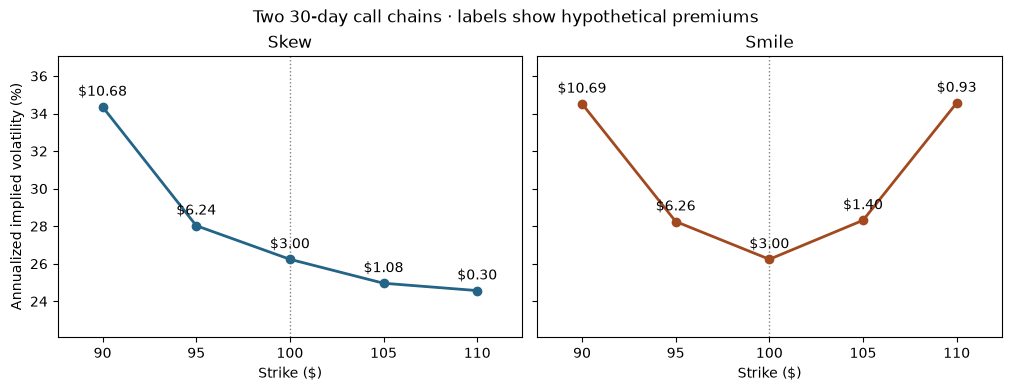

In [2]:
strikes = np.array([90, 95, 100, 105, 110])
quotes = [10.68, 6.24, 3.00, 1.08, 0.30]  # Synthetic quotes, same 30-day expiry
chain_iv = [implied_volatility(price, spot, k, years) for price, k in zip(quotes, strikes)]

smile_quotes = [10.69, 6.26, 3.0, 1.4, 0.93]  # A second illustrative call chain
smile_iv = [implied_volatility(price, spot, k, years) for price, k in zip(smile_quotes, strikes)]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, vols, premiums, title, color in zip(
    axes, [chain_iv, smile_iv], [quotes, smile_quotes],
    ["Skew", "Smile"], ["#236487", "#a24920"]
):
    ax.axvline(spot, color="grey", linestyle=":", linewidth=1)
    ax.plot(strikes, np.array(vols) * 100, "o-", color=color, linewidth=2)
    for k, price, vol in zip(strikes, premiums, vols):
        ax.annotate(f"${price:.2f}", (k, vol * 100), xytext=(0, 8),
                    textcoords="offset points", ha="center")
    ax.margins(x=0.12, y=0.25)
    ax.set(xticks=strikes, xlabel="Strike ($)", title=title)
axes[0].set_ylabel("Annualized implied volatility (%)")
fig.suptitle("Two 30-day call chains · labels show hypothetical premiums")
plt.show()

## From one contract to an index

The single-call IV above depends on strike, expiry and pricing model. **VIX** combines S&P 500 index option quotes across many strikes and two maturities to target a constant 30-calendar-day horizon. In variance terms, $(\mathrm{VIX}/100)^2$ approximates the annualized variance priced under the risk-neutral measure. A reading of 20 translates into a 30-day implied volatility of about $20\%\sqrt{30/365}=5.7\%$. That scale describes the size of a move in either direction.

Your HAR forecast targets future realized variance under the historical return process. Options also price investors’ willingness to pay for protection. To compare the two, align the underlying, horizon, units and overnight coverage, then score both against the same future observations. Here, the preceding 30 days provide a simple persistence forecast. [Cboe VIX methodology](https://cdn.cboe.com/resources/indices/governance/Volatility_Index_Methodology_Cboe_Volatility_Index.pdf)

## Market data · VIX versus the volatility that followed

At each month-end trading close $t$, line up three quantities around the same date:

| Previous 30 calendar days | Close at $t$ | Next 30 calendar days |
|:--|:--|:--|
| **Trailing realized vol** is known at $t$. Carry it forward as a simple forecast. | **VIX** is available at the close of its session. | **Forward realized vol** becomes known after the window. |

We compute annualized realized volatility as $100\sqrt{(365/30)\sum_i r_i^2}$, using S&P 500 close-to-close log returns whose **ending dates** fall in $(t-30,t]$ or $(t,t+30]$. Weekend and holiday moves enter in the next available close-to-close return. If the end date falls on a nontrading day, there is no separate return there. All three series are in annualized percent. Daily returns include the net overnight move but lose intraday detail. With 5-minute data you would sum squared intraday returns and add squared overnight returns for a close-to-close measure.

The historical sample uses the last trading date of each month from 2018 to 2024. Some adjacent 30-day windows overlap, so the comparisons are descriptive. The official VIX and S&P 500 closing observations are matched by session date. [Cboe VIX history](https://cdn.cboe.com/api/global/us_indices/daily_prices/VIX_History.csv) · [Yahoo Finance S&P 500 history](https://finance.yahoo.com/quote/%5EGSPC/history/)

In [3]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np

market = np.genfromtxt(
    Path("data/spx_vix_daily.csv"), delimiter=",", names=True, dtype=None, encoding="utf-8"
)
dates = market["date"].astype("datetime64[D]")
months = dates.astype("datetime64[M]")
month_end = np.r_[months[1:] != months[:-1], True]
in_study = (dates >= np.datetime64("2018-01-01")) & (dates < np.datetime64("2025-01-01"))
origins = dates[month_end & in_study]

horizon = np.timedelta64(30, "D")
assert dates[0] <= origins[0] - horizon and dates[-1] >= origins[-1] + horizon
return_dates = dates[1:]
squared_returns = np.diff(np.log(market["spx_close"])) ** 2
cumulative_variance = np.r_[0.0, np.cumsum(squared_returns)]

# Each index counts the returns ending on or before that window boundary.
start = np.searchsorted(return_dates, origins - horizon, side="right")
middle = np.searchsorted(return_dates, origins, side="right")
end = np.searchsorted(return_dates, origins + horizon, side="right")
scale = 365 / 30
trailing_rv = 100 * np.sqrt(scale * (cumulative_variance[middle] - cumulative_variance[start]))
forward_rv = 100 * np.sqrt(scale * (cumulative_variance[end] - cumulative_variance[middle]))
vix = market["vix_close"][month_end & in_study]

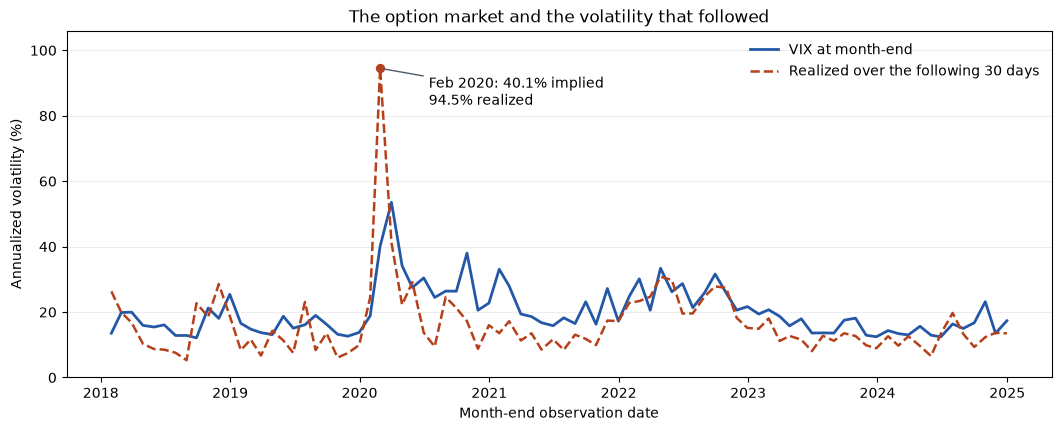

In [4]:
implied_color, realized_color = "#2458a7", "#b64019"
fig, ax = plt.subplots(figsize=(10.5, 4.2), layout="constrained")
ax.plot(origins, vix, color=implied_color, lw=2, label="VIX at month-end")
ax.plot(
    origins, forward_rv, color=realized_color, lw=1.8, linestyle="--",
    label="Realized over the following 30 days",
)
crisis = np.argmax(forward_rv)
ax.scatter(origins[crisis], forward_rv[crisis], s=32, zorder=3, color=realized_color)
ax.annotate(
    "Feb 2020: 40.1% implied\n94.5% realized",
    (origins[crisis], forward_rv[crisis]), xytext=(35, -5), textcoords="offset points",
    va="top", arrowprops={"arrowstyle": "-", "color": "#505b6a"},
)
ax.set(
    title="The option market and the volatility that followed",
    xlabel="Month-end observation date",
    ylabel="Annualized volatility (%)",
    ylim=(0, 106),
)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(axis="y", alpha=0.22)
ax.legend(loc="upper right", frameon=False)
plt.show()

At each point on the chart, both values are plotted at the **start** of the forward window. The dashed line is what we learned later. February 2020 illustrates why a high implied reading can still be overtaken by a much larger realized move.

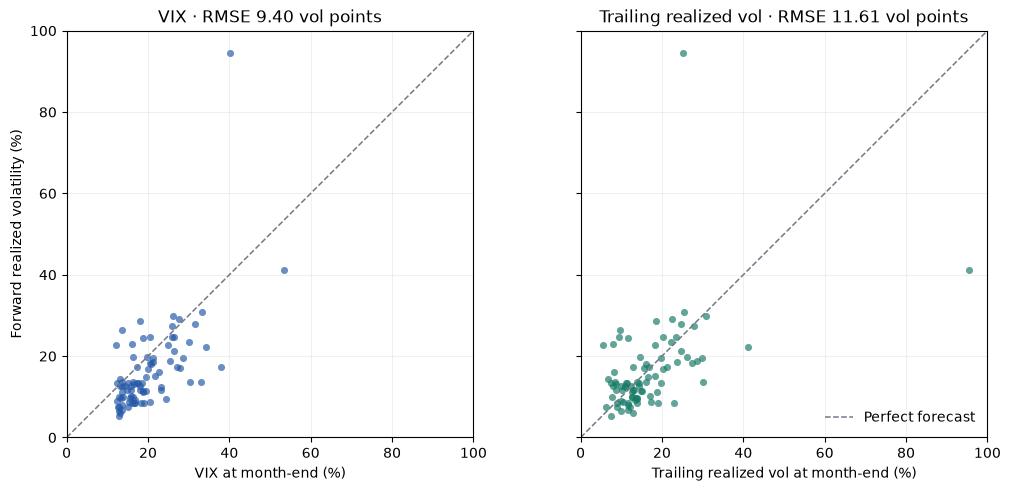

84 months | average VIX 20.10% | average forward RV 16.33%
Mean VIX minus forward RV: +3.77 vol points
VIX above forward RV: 69 of 84 months


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.8), layout="constrained", sharex=True, sharey=True)
limit = 100
for ax, signal, label, color in zip(
    axes, (vix, trailing_rv), ("VIX", "Trailing realized vol"), (implied_color, "#177b67")
):
    rmse = np.sqrt(np.mean((signal - forward_rv) ** 2))
    ax.plot([0, limit], [0, limit], color="#707987", lw=1.1, ls="--", label="Perfect forecast")
    ax.scatter(signal, forward_rv, color=color, alpha=0.68, s=26, linewidths=0)
    ax.set(
        title=f"{label} · RMSE {rmse:.2f} vol points", xlabel=f"{label} at month-end (%)",
        xlim=(0, limit), ylim=(0, limit), aspect="equal",
    )
    ax.grid(alpha=0.18)
axes[0].set_ylabel("Forward realized volatility (%)")
axes[1].legend(loc="lower right", frameon=False)
plt.show()

print(f"{len(vix)} months | average VIX {vix.mean():.2f}% | average forward RV {forward_rv.mean():.2f}%")
print(f"Mean VIX minus forward RV: {(vix - forward_rv).mean():+.2f} vol points")
print(f"VIX above forward RV: {np.count_nonzero(vix > forward_rv)} of {len(vix)} months")

**Read the scatterplots:** points below the diagonal had less realized volatility than the starting signal suggested. VIX was above forward realized volatility in 69 of 84 months and had lower RMSE than the trailing-vol baseline in this sample. The average gap combines pricing effects, forecast errors and differences in how the measures are constructed. A variance risk premium is defined in variance units using a real-world **expected** variance, so a volatility gap against one realized outcome is an illustration of the difference.

To connect this with HAR or GARCH, use the model to forecast the same forward variance window using data available at $t$. Compare that forecast and the option-implied variance against the same realized variance target.

## One window with actual five-minute realized variance

On January 29, 2021, VIX closed at 33.09. What would your five-minute estimator have recorded over the following 30 calendar days? The Oxford–Man Realized Library supplies each session’s **sum of squared five-minute returns**, along with opening and closing prices. Start at the January 29 close. Add daily intraday variances, then include squared close-to-open returns to capture overnight gaps. Add the components **before** taking the square root. [Oxford–Man Realized Library](https://shephard.scholars.harvard.edu/publications/realized-library)

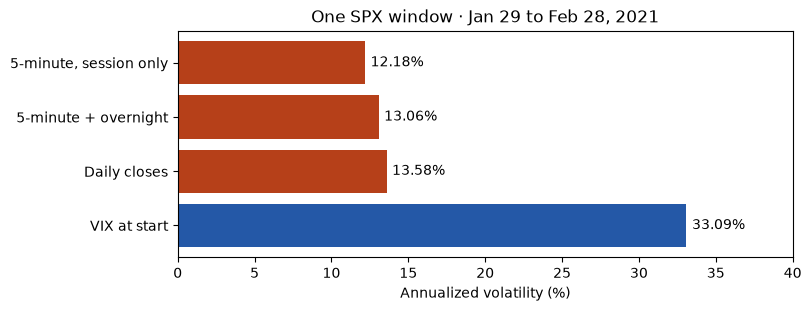

In [6]:
sample = np.genfromtxt("data/spx_intraday_example.csv", delimiter=",", names=True,
                       dtype=None, encoding="utf-8")
intraday = sample["rv5"][1:].sum()
overnight = np.log(sample["open_price"][1:] / sample["close_price"][:-1])
daily = np.diff(np.log(sample["close_price"]))
variance_totals = np.array([intraday, intraday + overnight @ overnight, daily @ daily])
measured = 100 * np.sqrt(365 / 30 * variance_totals)
initial_vix = market["vix_close"][market["date"] == "2021-01-29"].item()

fig, ax = plt.subplots(figsize=(8, 3), layout="constrained")
bars = ax.barh(["5-minute, session only", "5-minute + overnight", "Daily closes", "VIX at start"],
               [*measured, initial_vix], color=["#b64019"] * 3 + ["#2458a7"])
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.invert_yaxis()
ax.set(xlim=(0, 40), xlabel="Annualized volatility (%)", title="One SPX window · Jan 29 to Feb 28, 2021")
plt.show()

Adding overnight gaps lifts measured volatility from **12.18% to 13.06%**. Daily closes give **13.58%** over the same window. Sampling changes the estimate, but the much larger gap to the initial **33.09%** VIX remains. In this particular month, options priced considerably more variance than subsequently materialized.